In [8]:
#pip install scipy
#!pip install statsmodels
!pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------- ----------------------------- 2.1/8.4 MB 11.7 MB/s eta 0:00:01
   --------------------- ------------------ 4.5/8.4 MB 11.7 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.4 MB 11.7 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 9.7 MB/s  0:00:00

   ---------- ----------------------------- 1/4 [cloudpickle]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   ----


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
EM_NOTEBOOK = "ipykernel" in sys.modules
if EM_NOTEBOOK:
    from IPython import get_ipython
    get_ipython().run_line_magic("matplotlib", "inline")
else:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
 
warnings.filterwarnings("ignore")
try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
GOLD = ROOT / "dados" / "gold" / "history_gold.csv"
SILVER = ROOT / "dados" / "silver" / "history_silver.csv"
OUT = ROOT / "graficos"
DOC = ROOT / "documentacao"
OUT.mkdir(exist_ok=True)
DOC.mkdir(exist_ok=True)
 
BLUE, RED, GRAY, GREEN, ORANGE = "#4C78A8", "#E45756", "#B0B7C3", "#54A24B", "#F58518"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
 
 
def save(fig, name):
    fig.savefig(OUT / name, dpi=150, bbox_inches="tight", facecolor="white")
    if EM_NOTEBOOK:
        plt.show()
    plt.close(fig)
 
 
def show(df):
    if EM_NOTEBOOK:
        from IPython.display import display
        display(df)
    else:
        print(df.to_string())

In [12]:
# DADOS 

g = pd.read_csv(GOLD)
extra = ["Genero", "Renda_Mensal", "Multiplas_Linhas", "Streaming_TV", "Streaming_Filmes",
         "Servico_Telefonico", "Feedback_Cliente"]
s = pd.read_csv(SILVER, usecols=["ID_Cliente"] + extra)
s["Servico_Telefonico"] = s.Servico_Telefonico.str.strip().str.capitalize()
g = g.merge(s, on="ID_Cliente", how="left")
g["Contrato_PT"] = g.Contrato.map({"Month-to-month": "Mensal", "One year": "1 ano", "Two year": "2 anos"})
g["Internet_PT"] = g.Servico_Internet.map({"Fiber optic": "Fibra", "DSL": "DSL", "No": "Sem internet"})
g["Pagamento_PT"] = g.Metodo_Pagamento.map({
    "Electronic check": "Cheque eletrônico", "Mailed check": "Cheque correio",
    "Bank transfer (automatic)": "Transf. automática", "Credit card (automatic)": "Cartão automático"})
y = g.Cancelou

,variavel,tipo,cramers_v,p_valor,correlacao_r,no_gold,forca
0,Contrato,categórica/binária,0.404,2.2e-200,NaN,True,forte
1,Tempo_Permanencia_Meses,numérica,0.356,3.3e-153,-0.344,True,forte
2,Cobranca_Por_Servico,numérica,0.332,2.0e-133,0.278,True,forte
3,Servico_Internet,categórica/binária,0.324,5.5e-129,NaN,True,forte
4,Metodo_Pagamento,categórica/binária,0.297,1.4e-107,NaN,True,moderada
5,Streaming_Filmes,categórica/binária,0.236,6.0e-69,NaN,False,moderada
6,Streaming_TV,categórica/binária,0.234,1.1e-67,NaN,False,moderada
7,Cobranca_Mensal,numérica,0.219,2.7e-57,0.201,True,moderada
8,Qtd_Servicos_Protecao,categórica/binária,0.218,1.0e-56,-0.162,True,moderada
9,Qtd_Servicos_Total,numérica,0.218,1.1e-56,-0.007,True,moderada


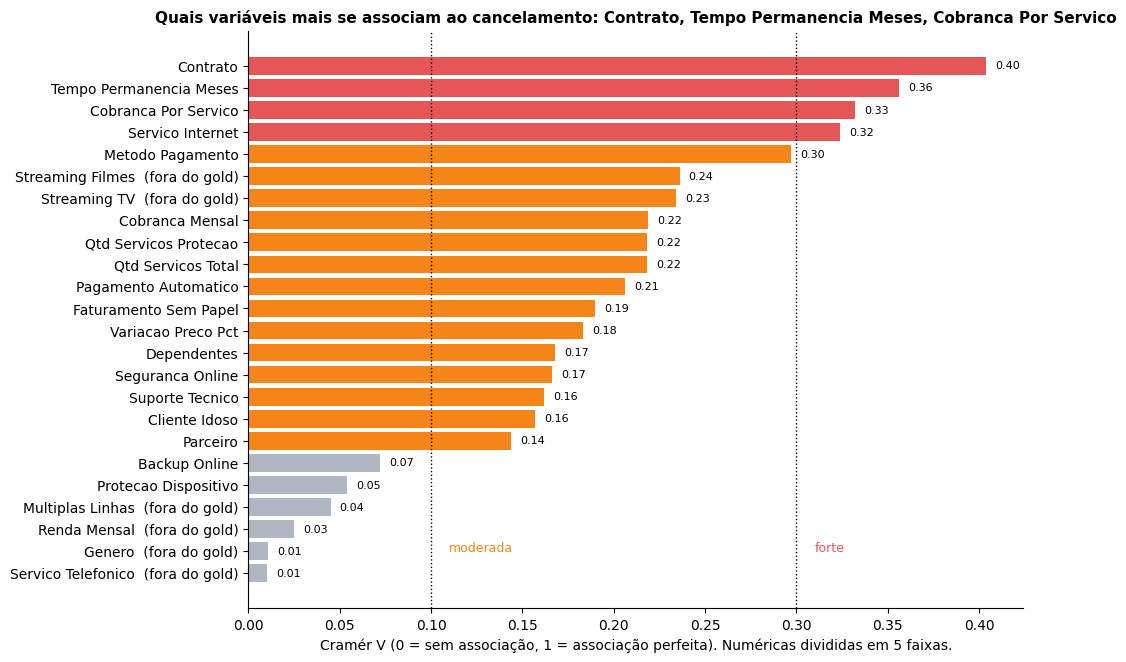

In [13]:
FORA_GOLD = ["Genero", "Renda_Mensal", "Multiplas_Linhas", "Streaming_TV", "Streaming_Filmes", "Servico_Telefonico"]
CANDIDATAS = ["Tempo_Permanencia_Meses", "Cobranca_Mensal", "Cobranca_Por_Servico", "Qtd_Servicos_Protecao",
              "Qtd_Servicos_Total", "Variacao_Preco_Pct", "Contrato", "Servico_Internet", "Metodo_Pagamento",
              "Pagamento_Automatico", "Faturamento_Sem_Papel", "Seguranca_Online", "Backup_Online",
              "Protecao_Dispositivo", "Suporte_Tecnico", "Cliente_Idoso", "Parceiro", "Dependentes"] + FORA_GOLD
 
 
def cramers_v(x, yy):
    tab = pd.crosstab(x, yy)
    chi2, p, _, _ = chi2_contingency(tab, correction=False)
    return np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1))), p
 
 
rows = []
for c in CANDIDATAS:
    x, yy = g[c], y
    ok = x.notna()
    x, yy = x[ok], yy[ok]
    numerica = x.dtype.kind in "if" and x.nunique() > 6
    xb = pd.qcut(x, 5, duplicates="drop") if numerica else x
    v, p = cramers_v(xb, yy)
    r = np.corrcoef(x, yy)[0, 1] if x.dtype.kind in "if" else np.nan
    rows.append({"variavel": c, "tipo": "numérica" if numerica else "categórica/binária",
                 "cramers_v": round(v, 3), "p_valor": p, "correlacao_r": round(r, 3) if r == r else np.nan,
                 "no_gold": c not in FORA_GOLD})
assoc = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
assoc["forca"] = pd.cut(assoc.cramers_v, [-1, 0.10, 0.30, 1], labels=["fraca/nula", "moderada", "forte"])
show(assoc.assign(p_valor=assoc.p_valor.map(lambda v: f"{v:.1e}")))
 
a = assoc.sort_values("cramers_v")
cores = a.forca.map({"forte": RED, "moderada": ORANGE, "fraca/nula": GRAY})
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh([v.replace("_", " ") + ("" if ng else "  (fora do gold)") for v, ng in zip(a.variavel, a.no_gold)],
        a.cramers_v, color=cores)
for i, v in enumerate(a.cramers_v):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8)
ax.axvline(0.10, color="k", ls=":", lw=1)
ax.axvline(0.30, color="k", ls=":", lw=1)
ax.set_xlabel("Cramér V (0 = sem associação, 1 = associação perfeita). Numéricas divididas em 5 faixas.")
top3 = ", ".join(assoc.variavel[:3].str.replace("_", " "))
ax.set_title(f"Quais variáveis mais se associam ao cancelamento: {top3}", fontsize=11)
ax.text(0.31, 1, "forte", color=RED, fontsize=9)
ax.text(0.11, 1, "moderada", color=ORANGE, fontsize=9)
save(fig, "10_associacao_com_cancelamento.png")

,OR,lo,hi,p
Contrato 2 anos (vs mensal),0.290,0.202,0.417,0.000
Sem internet (vs DSL),0.452,0.322,0.634,0.000
Contrato 1 ano (vs mensal),0.514,0.409,0.646,0.000
Segurança online,0.625,0.519,0.753,0.000
Suporte técnico,0.651,0.537,0.789,0.000
Permanência (+12 meses),0.693,0.653,0.734,0.000
Tem dependentes,0.827,0.681,1.004,0.055
Backup online,0.853,0.720,1.011,0.066
Tem parceiro,1.028,0.869,1.215,0.749
Proteção de dispositivo,1.036,0.866,1.240,0.699


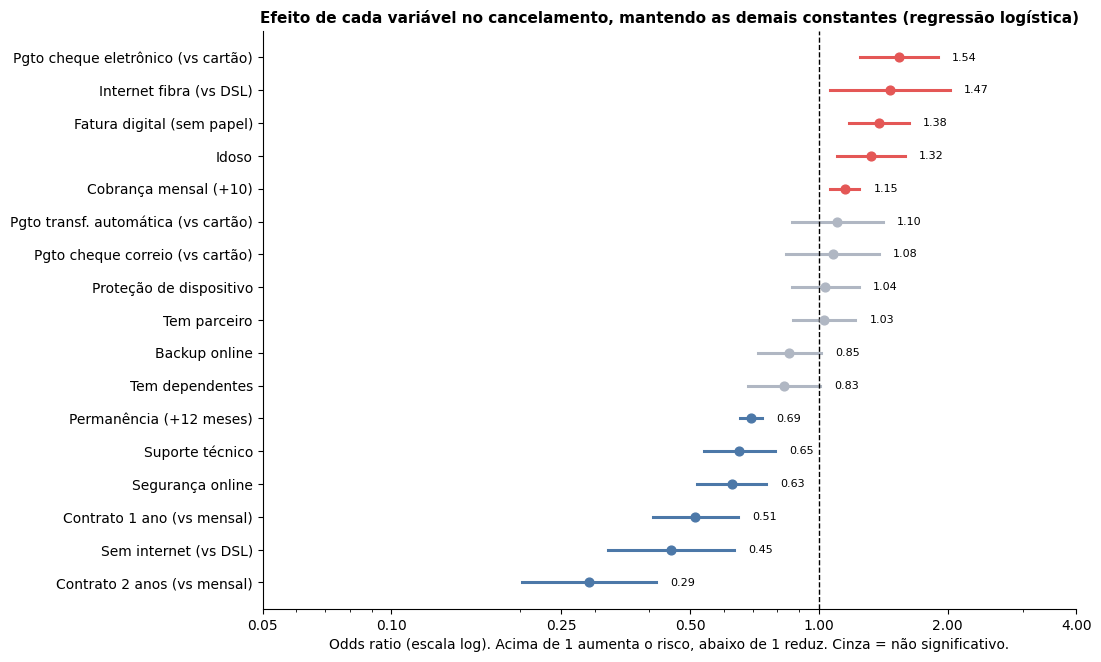

In [14]:
X = pd.DataFrame({
    "Permanência (+12 meses)": g.Tempo_Permanencia_Meses / 12,
    "Cobrança mensal (+10)": g.Cobranca_Mensal / 10,
    "Idoso": g.Cliente_Idoso, "Tem parceiro": g.Parceiro, "Tem dependentes": g.Dependentes,
    "Fatura digital (sem papel)": g.Faturamento_Sem_Papel,
    "Segurança online": g.Seguranca_Online, "Backup online": g.Backup_Online,
    "Proteção de dispositivo": g.Protecao_Dispositivo, "Suporte técnico": g.Suporte_Tecnico,
    "Contrato 1 ano (vs mensal)": (g.Contrato_PT == "1 ano").astype(int),
    "Contrato 2 anos (vs mensal)": (g.Contrato_PT == "2 anos").astype(int),
    "Internet fibra (vs DSL)": (g.Internet_PT == "Fibra").astype(int),
    "Sem internet (vs DSL)": (g.Internet_PT == "Sem internet").astype(int),
    "Pgto cheque eletrônico (vs cartão)": (g.Pagamento_PT == "Cheque eletrônico").astype(int),
    "Pgto cheque correio (vs cartão)": (g.Pagamento_PT == "Cheque correio").astype(int),
    "Pgto transf. automática (vs cartão)": (g.Pagamento_PT == "Transf. automática").astype(int),
}).astype(float)
lr = sm.Logit(y, sm.add_constant(X)).fit(disp=0)
ci = np.exp(lr.conf_int())
res = pd.DataFrame({"OR": np.exp(lr.params), "lo": ci[0], "hi": ci[1], "p": lr.pvalues}).drop("const").sort_values("OR")
show(res.round(3))
 
fig, ax = plt.subplots(figsize=(10.5, 7.5))
for i, (nome, r) in enumerate(res.iterrows()):
    cor = GRAY if r.lo <= 1 <= r.hi else (RED if r.OR > 1 else BLUE)
    ax.plot([r.lo, r.hi], [i, i], color=cor, lw=2.2)
    ax.scatter(r.OR, i, color=cor, zorder=3, s=40)
    ax.text(r.hi * 1.08, i, f"{r.OR:.2f}", va="center", fontsize=8)
ax.axvline(1, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.05, 0.1, 0.25, 0.5, 1, 2, 4])
ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.set_yticks(range(len(res)))
ax.set_yticklabels(res.index)
ax.set_xlabel("Odds ratio (escala log). Acima de 1 aumenta o risco, abaixo de 1 reduz. Cinza = não significativo.")
ax.set_title("Efeito de cada variável no cancelamento, mantendo as demais constantes (regressão logística)")
save(fig, "11_efeito_ajustado_odds_ratio.png")

,variavel,queda_auc,dp
15,Contrato,0.1065,0.0120
0,Tempo_Permanencia_Meses,0.0697,0.0091
16,Servico_Internet,0.0321,0.0052
1,Cobranca_Mensal,0.0303,0.0051
9,Seguranca_Online,0.0044,0.0017
17,Metodo_Pagamento,0.0036,0.0021
3,Qtd_Servicos_Protecao,0.0036,0.0015
12,Suporte_Tecnico,0.0035,0.0011
6,Cliente_Idoso,0.0029,0.0011
5,Variacao_Preco_Pct,0.0029,0.0024


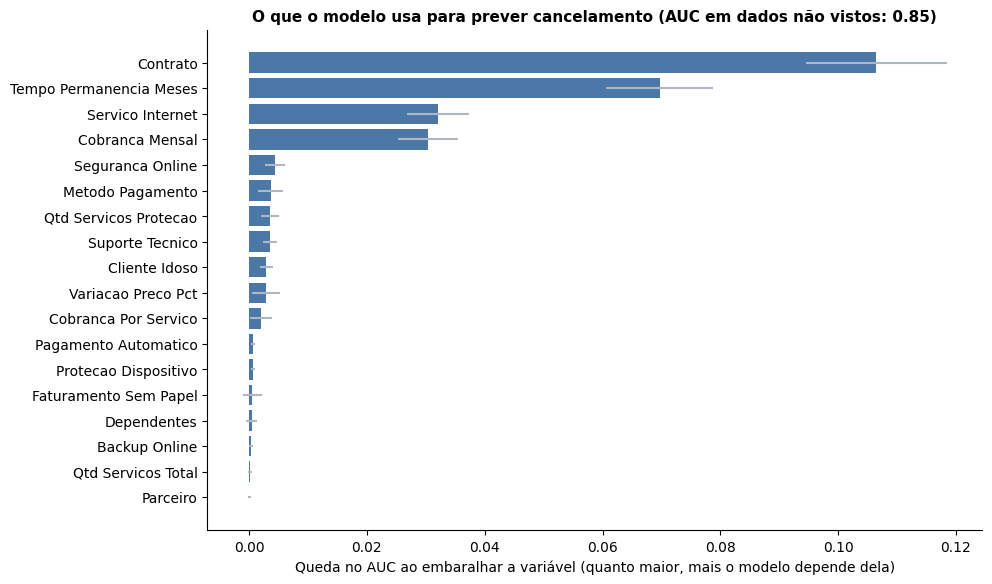

In [15]:
NUM = ["Tempo_Permanencia_Meses", "Cobranca_Mensal", "Cobranca_Por_Servico", "Qtd_Servicos_Protecao",
       "Qtd_Servicos_Total", "Variacao_Preco_Pct"]
BIN = ["Cliente_Idoso", "Parceiro", "Dependentes", "Seguranca_Online", "Backup_Online", "Protecao_Dispositivo",
       "Suporte_Tecnico", "Pagamento_Automatico", "Faturamento_Sem_Papel"]
CAT = ["Contrato", "Servico_Internet", "Metodo_Pagamento"]
F = NUM + BIN + CAT
Xtr, Xte, ytr, yte = train_test_split(g[F], y, test_size=0.25, stratify=y, random_state=0)
pipe = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)],
                               remainder="passthrough")),
    ("gb", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, random_state=0)),
]).fit(Xtr, ytr)
auc = roc_auc_score(yte, pipe.predict_proba(Xte)[:, 1])
pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=15, random_state=0)
imp = pd.DataFrame({"variavel": F, "queda_auc": pi.importances_mean, "dp": pi.importances_std}).sort_values("queda_auc")
show(imp.sort_values("queda_auc", ascending=False).round(4))
 
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(imp.variavel.str.replace("_", " "), imp.queda_auc, xerr=imp.dp, color=BLUE, ecolor=GRAY)
ax.set_xlabel("Queda no AUC ao embaralhar a variável (quanto maior, mais o modelo depende dela)")
ax.set_title(f"O que o modelo usa para prever cancelamento (AUC em dados não vistos: {auc:.2f})")
save(fig, "12_importancia_no_modelo.png")